# Personalized PDP Recommendations v2 - synthetic A/B readout

Experiment 202 uses 50,000 simulated customers. The supplied segment configuration
sets the expected control rate to 3.800% and treatment rate to 4.287%, a 12.82%
relative lift. No real v2 database is required; these are simulation inputs.


In [1]:
from pathlib import Path
import sys, json, duckdb, pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
while not (ROOT / 'seed_experiment.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from analysis import stats as ab
import make_figures as mk
con = duckdb.connect(str(ROOT / 'data/experiment.duckdb'), read_only=True)
def sql(name):
    return con.execute((ROOT / 'sql' / name).read_text(encoding='utf-8')).df()


## 1. SRM first - stop on invalid assignment
Only assignment data are inspected here. No conversion, guardrail, or chart is
computed before the chi-square gate succeeds (p >= 0.001).


In [2]:
assign = con.execute("select * from experiment_assignments where experiment_id = 202").df()
chi2, p_srm = mk.validate_assignments(assign)
display(sql('01_srm_check.sql'))
print(f'SRM FIRST: chi-square={chi2:.4f}, p={p_srm:.6f}; PASS')


,variant_name,n,total,observed_share,expected_share
0,control,25022,50000.0,0.5004,0.5
1,treatment,24978,50000.0,0.4996,0.5


SRM FIRST: chi-square=0.0387, p=0.844004; PASS


## 2. Simulation inputs and sample-size context
The population rates below are weighted from the supplied segment assumptions.
Historical data is optional future production validation, not a dependency for
this exercise. The fixed 50,000-customer sample is required by the simulation task.


In [3]:
config = json.loads((ROOT / 'data/seed_config.json').read_text(encoding='utf-8'))
baseline = config['control_probability']
display(pd.DataFrame(config['segments']).T)
print(f'Expected control: {baseline:.3%}; treatment: {config["treatment_probability"]:.3%}')
print(f'Expected relative lift: {config["expected_relative_lift"]:.2%}')
print(config['baseline_provenance'])
for relative in [0.10, config['expected_relative_lift'], 0.15]:
    n = ab.required_sample_per_arm(baseline, baseline * relative)
    print(f'Target {relative:.2%}: MDE={100*baseline*relative:.3f}pp; approximately {n:,}/arm')


,share,control_cr,treatment_relative_lift
apparel_beauty,0.50,0.042,0.15
electronics,0.25,0.032,0.08
home,0.25,0.036,0.12


Expected control: 3.800%; treatment: 4.287%
Expected relative lift: 12.82%
Synthetic segment configuration; not measured historical data
Target 10.00%: MDE=0.380pp; approximately 41,641/arm
Target 12.82%: MDE=0.487pp; approximately 25,678/arm
Target 15.00%: MDE=0.570pp; approximately 18,927/arm


## 3. Customer-level paid conversion
ITT denominator: all assigned customers. Numerator: at least one paid order in
[assignment, assignment + 7 days). Independent Bernoulli draws use each category
control rate and its own treatment multiplier. Observed lift varies from expectation.


,customers,converters,conversion_rate,revenue,revenue_per_customer,aov,refund_rate,repeat_30d_rate,pmt_failure_rate
variant_name,,,,,,,,,
control,25022,949.0,0.0379,2339458.0,93.50,2465.18,0.0116,0.2276,0.0165
treatment,24978,1007.0,0.0403,2614098.0,104.66,2595.93,0.0238,0.1917,0.0171


Control 3.793%; treatment 4.032%
Lift +6.30% relative; +0.239pp absolute
95% absolute CI [-0.101, +0.579]pp
Approximate relative CI [-2.66%, +15.26%]
Z=1.378, p=0.1683; significant at .05: False


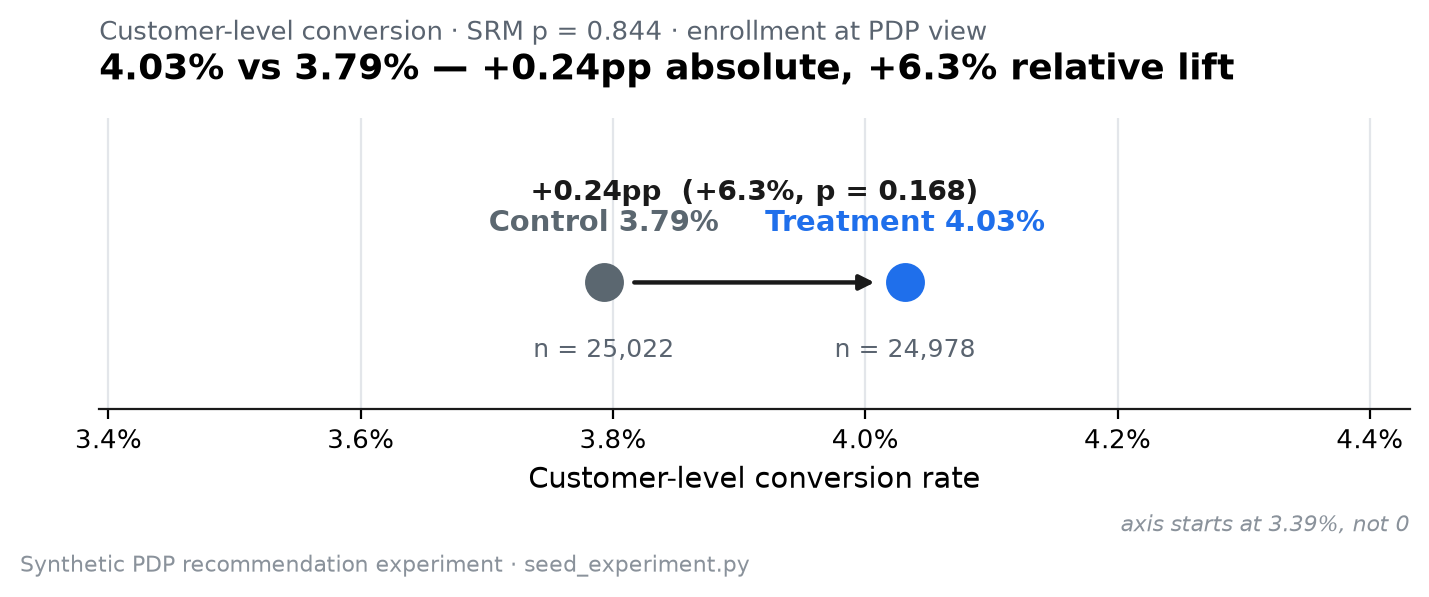

In [4]:
m = sql('03_per_variant_metrics.sql').set_index('variant_name')
display(m)
c, t = m.loc['control'], m.loc['treatment']
r = ab.lift_with_ci(int(c.converters), int(c.customers), int(t.converters), int(t.customers))
print(f'Control {r.p_control:.3%}; treatment {r.p_treatment:.3%}')
print(f'Lift {r.rel_lift:+.2%} relative; {r.abs_lift*100:+.3f}pp absolute')
print(f'95% absolute CI [{r.abs_ci[0]*100:+.3f}, {r.abs_ci[1]*100:+.3f}]pp')
print(f'Approximate relative CI [{r.rel_ci[0]:+.2%}, {r.rel_ci[1]:+.2%}]')
print(f'Z={r.z:.3f}, p={r.p_value:.4f}; significant at .05: {r.p_value < .05}')
if abs(r.z) >= 70:
    raise ValueError('Extreme Z: audit the seed/denominators before interpreting results.')
orders = con.execute('select * from orders').df()
M = mk.compute_metrics(mk._customer_outcomes(assign, orders))
mk.apply_theme()
for render in [mk.fig1_forest, mk.fig2_dumbbell, mk.fig3_guardrails]:
    render(M)
display(Image(filename=str(ROOT / 'figures/02_conversion_compare.png')))


## 4. Guardrails and the real tradeoff
Refund probability, bounce probability, and latency are seeded higher in treatment.
Observed guardrails are reported honestly even when random variation reverses an
expected direction. Refund and repeat flags model mature outcomes. Bounce and
latency are synthetic customer summaries, not actual session telemetry.


,refund_rate,repeat_30d_rate,pmt_failure_rate,aov,revenue_per_customer
variant_name,,,,,
control,0.0116,0.2276,0.0165,2465.18,93.50
treatment,0.0238,0.1917,0.0171,2595.93,104.66


refund: difference +1.224pp; 95% CI [+0.062, +2.387]pp
repeat: difference -3.595pp; 95% CI [-7.204, +0.014]pp
pmt: difference +0.063pp; 95% CI [-0.162, +0.288]pp


,bounce_rate,p95_latency_ms
variant_name,,
control,0.251499,1477.536404
treatment,0.265233,1557.975408


Bounce difference +1.373pp; 95% CI [+0.606, +2.141]pp
Proposed tolerances: refund +0.5pp, bounce +1.0pp, p95 latency +100ms.
Compare uncertainty to tolerances; a non-significant regression does not establish safety.


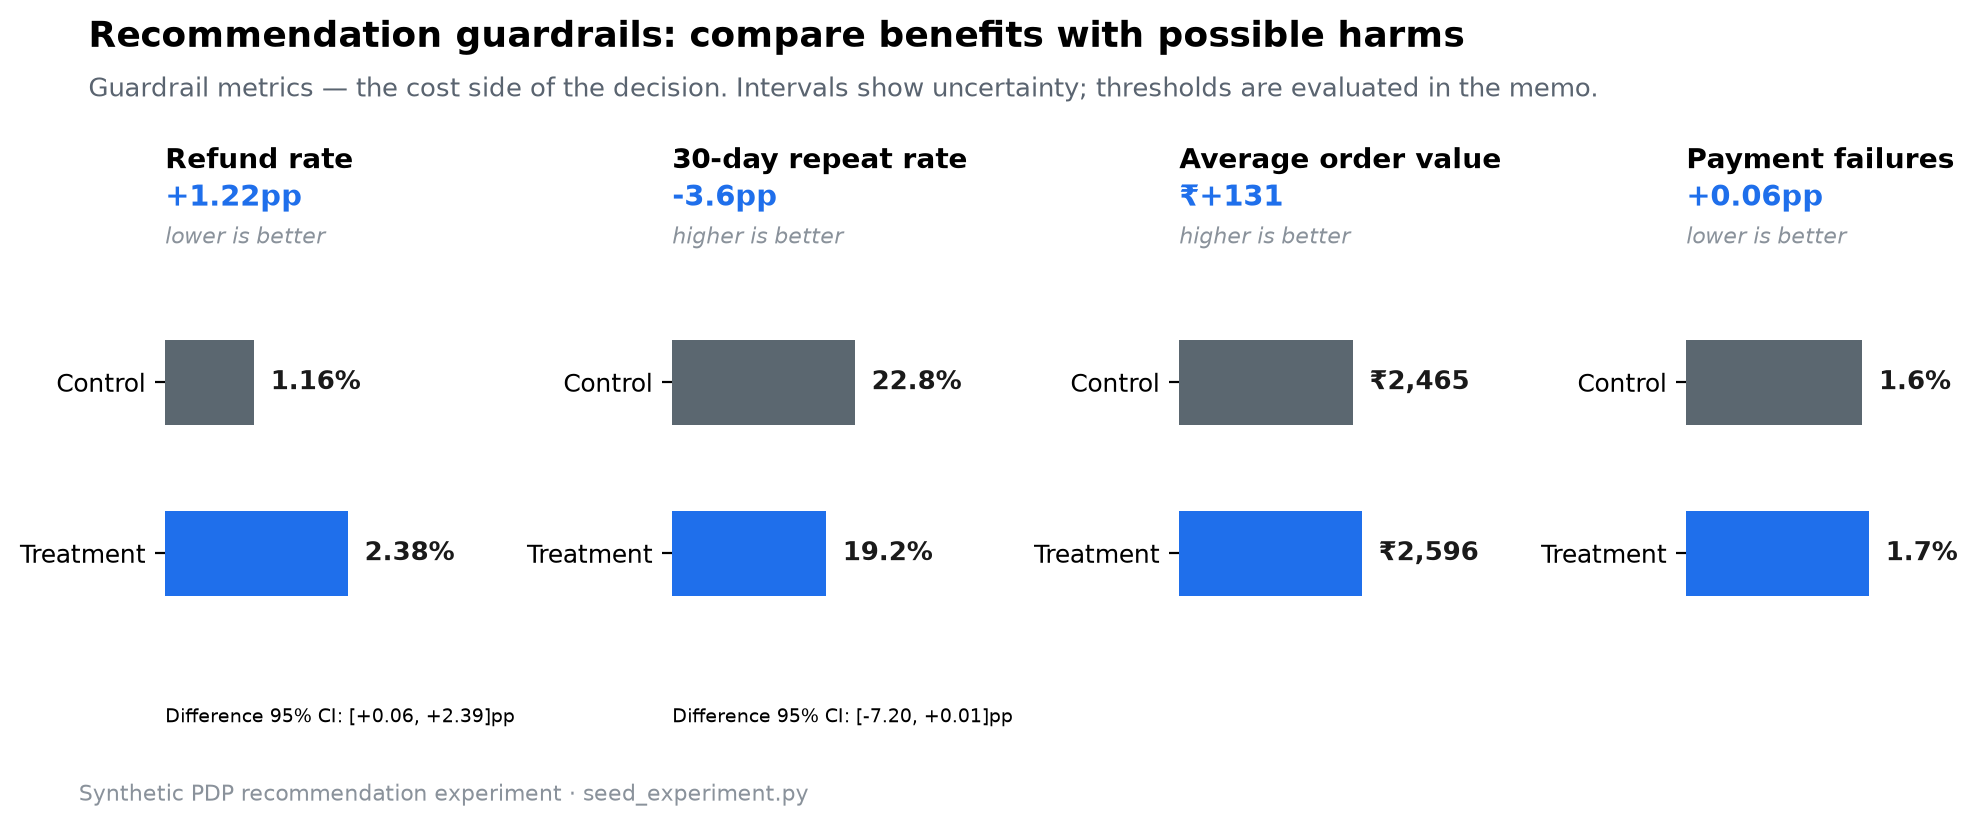

In [5]:
display(m[['refund_rate', 'repeat_30d_rate', 'pmt_failure_rate', 'aov', 'revenue_per_customer']])
for key in ['refund', 'repeat', 'pmt']:
    result = M[key]
    print(f'{key}: difference {result.abs_lift*100:+.3f}pp; 95% CI '
          f'[{result.abs_ci[0]*100:+.3f}, {result.abs_ci[1]*100:+.3f}]pp')
g = assign.groupby('variant_name').agg(bounce_rate=('bounced', 'mean'),
                                      p95_latency_ms=('pdp_latency_ms', lambda x: x.quantile(.95)))
display(g)
ac = assign[assign.variant_name == 'control']; at = assign[assign.variant_name == 'treatment']
bounce = ab.lift_with_ci(int(ac.bounced.sum()), len(ac), int(at.bounced.sum()), len(at))
print(f'Bounce difference {bounce.abs_lift*100:+.3f}pp; 95% CI '
      f'[{bounce.abs_ci[0]*100:+.3f}, {bounce.abs_ci[1]*100:+.3f}]pp')
print('Proposed tolerances: refund +0.5pp, bounce +1.0pp, p95 latency +100ms.')
print('Compare uncertainty to tolerances; a non-significant regression does not establish safety.')
display(Image(filename=str(ROOT / 'figures/03_guardrails.png')))


## 5. Exploratory segments
Nine tests: three category, three device, three country. Bonferroni alpha=0.05/9.
The generator imposes category lifts of 15%, 8%, and 12%. Estimates contain noise;
separate segment significance tests do not demonstrate treatment-by-segment interaction.


,cut,segment,relative_lift,p,passes_bonferroni
0,category,apparel_beauty,0.052547,0.388692,False
1,category,electronics,0.022834,0.821749,False
2,category,home,0.108280,0.248785,False
3,country,India,0.093988,0.072948,False
4,country,Other,-0.055824,0.710106,False
5,country,United States,-0.031956,0.788816,False
6,device,desktop,-0.011998,0.866443,False
7,device,mobile,0.116039,0.065877,False
8,device,tablet,0.077897,0.664273,False


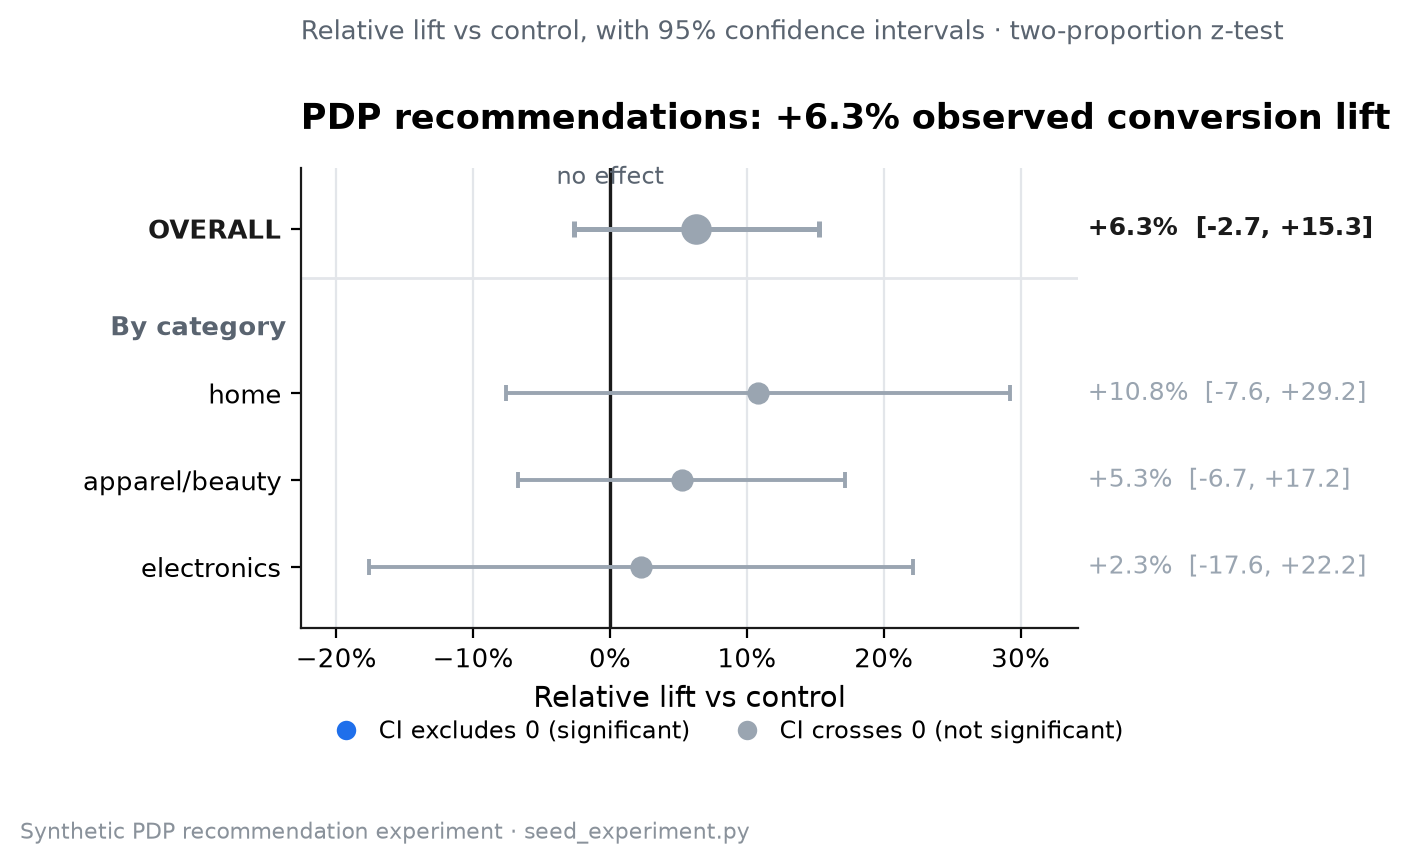

In [6]:
segments = sql('04_segmentation.sql')
rows = []
for (cut, segment), d in segments.groupby(['cut', 'segment']):
    cc = d[d.variant_name == 'control'].iloc[0]
    tt = d[d.variant_name == 'treatment'].iloc[0]
    rr = ab.lift_with_ci(int(cc.converters), int(cc.customers), int(tt.converters), int(tt.customers))
    rows.append({'cut': cut, 'segment': segment, 'relative_lift': rr.rel_lift,
                 'p': rr.p_value, 'passes_bonferroni': rr.p_value < .05/9})
display(pd.DataFrame(rows))
display(Image(filename=str(ROOT / 'figures/01_lift_forest.png')))


## 6. Decision
This synthetic exercise validates the workflow. It cannot establish production
benefit or safety. A live decision needs real randomized outcomes, mature guardrails,
and contribution margin. Revenue per customer is before refunds and uses INR.
See [decision_memo.md](../decision_memo.md).


In [7]:
print(f'Revenue/customer: INR {c.revenue_per_customer:.2f} -> {t.revenue_per_customer:.2f}')
print(f'Approximate conversion lower bound > 4% relative: {r.rel_ci[0] > .04}')
print(f'Refund upper CI below +0.5pp: {M["refund"].abs_ci[1] < .005}')
print(f'Bounce upper CI below +1.0pp: {bounce.abs_ci[1] < .01}')
con.close()


Revenue/customer: INR 93.50 -> 104.66
Approximate conversion lower bound > 4% relative: False
Refund upper CI below +0.5pp: False
Bounce upper CI below +1.0pp: False
